# 02 - SDXL baseline: text + frozen scribble ControlNet + frozen IP-Adapter

Team One Sheep Army. Runs the four baseline modes on the frozen `pilot_v1` test split and saves images to Drive.
No training. Everything is frozen.

| Mode | Caption | ControlNet (sketch) | IP-Adapter (reference) |
|---|---|---|---|
| `text` | on | off | off |
| `text_sketch` | on | on | off |
| `text_ref` | on | off | on |
| `text_sketch_ref` | on | on | on |

**Memory design (T4 = 14.5 GB GPU, but only ~12.7 GB system RAM).**
Loading the whole pipeline at once, or using CPU offload, keeps ~11 GB of weights in system RAM and crashes Colab. So this notebook:
1. Loads each component separately straight onto the GPU (system RAM never holds more than one at a time).
2. Encodes all captions and reference images once, caches the tiny embeddings, then deletes the text encoders and image encoder (~3 GB).
3. Generates with only UNet + ControlNet + VAE resident (~8.3 GB of weights), leaving room for activations. Expected peak: ~11-12 GB. The sanity cell prints the measured value.

Run order: cells top to bottom. Use `Runtime > Change runtime type > T4 GPU`. Dataset files and the manifest persist in Drive. Model downloads (~11 GB) repeat each session unless `CACHE_MODELS_ON_DRIVE = True`.

In [17]:
# ---- CONFIG: edit here only ----
DRIVE_ROOT = "/content/drive/MyDrive/sketchy_dataset_one_sketch"
ZIP_PATH = f"{DRIVE_ROOT}/pilot_v1.zip"
LOCAL_DATA = "/content/pilot_v1"
RUN_NAME = "sdxl_baseline_v1"
OUT_ROOT = f"{DRIVE_ROOT}/sdxl_runs/{RUN_NAME}"

SPLIT = "test"
MAX_ROWS = None          # set e.g. 8 for a quick dry run
RES = 768                # SDXL is happiest at 1024; 768 keeps the T4 safe. Try 1024 only if peak VRAM allows.
STEPS = 25
CFG = 7.0
NEG = "blurry, low quality, text, watermark, multiple objects, cropped"
SKETCH_DILATE = False    # thicken sketch lines slightly (the ControlNet prefers bolder lines)
CACHE_MODELS_ON_DRIVE = False   # True keeps ~11 GB of weights in Drive (needs the space)
RUN_GRID = True         # weight-grid generation for gate targets (see last section)
GRID_SPLIT = "train"
GRID_ROWS = 40
GRID_CS = [0.4, 0.7, 1.0]
GRID_IP = [0.2, 0.4, 0.6, 0.8]

# mode -> (controlnet_conditioning_scale, ip_adapter_scale)
MODES = {
    "text":            (0.0, 0.0),
    "text_sketch":     (1.0, 0.0),
    "text_ref":        (0.0, 0.6),
    "text_sketch_ref": (1.0, 0.6),
}

BASE_ID = "stabilityai/stable-diffusion-xl-base-1.0"
VAE_ID = "madebyollin/sdxl-vae-fp16-fix"          # stock SDXL VAE gives NaNs/black images in fp16 on T4
CN_ID = "xinsir/controlnet-scribble-sdxl-1.0"
IP_REPO = "h94/IP-Adapter"
IP_SUBFOLDER = "sdxl_models"
IP_WEIGHT = "ip-adapter_sdxl_vit-h.safetensors"   # ViT-H variant: smaller image encoder than the bigG one
ENC_SUBFOLDER = "models/image_encoder"

# metadata.jsonl column names. The first match in each list is used. Edit if the schema check below complains.
FIELD_MAP = {
    "id":        ["id", "image_id", "photo_id", "uid"],
    "split":     ["split"],
    "target":    ["target", "photo", "photo_path", "image", "target_path"],
    "sketch":    ["sketch", "sketch_path", "condition_sketch"],
    "reference": ["reference", "reference_path", "reference_image", "ref", "ref_path"],
    "caption":   ["caption", "prompt", "text"],
    "category":  ["category", "class", "label"],
}

In [3]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
from google.colab import drive

try:
    print("Attempting to mount Google Drive...")
    drive.mount("/content/drive")
    print("Drive mounted successfully!")
except Exception as e:
    print(f"Google Drive mount failed: {e}")
    print("Please ensure you approved the authentication prompt. If you are not using Drive, make sure to change DRIVE_ROOT to a local path.")

if CACHE_MODELS_ON_DRIVE:
    os.environ["HF_HOME"] = f"{DRIVE_ROOT}/hf_cache"
    os.makedirs(os.environ["HF_HOME"], exist_ok=True)

Attempting to mount Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted successfully!


In [4]:
!pip install -q -U diffusers transformers accelerate safetensors
import torch, diffusers, transformers
print("torch", torch.__version__, "| diffusers", diffusers.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0), "| total GB:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))

torch 2.11.0+cu130 | diffusers 0.42.0 | transformers 5.20.2
GPU: Tesla T4 | total GB: 15.6


In [5]:
import glob, json, zipfile, hashlib, time
from PIL import Image, ImageOps, ImageFilter
import numpy as np

if not os.path.isdir(LOCAL_DATA) or not glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True):
    os.makedirs(LOCAL_DATA, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(LOCAL_DATA)
meta_path = glob.glob(f"{LOCAL_DATA}/**/metadata.jsonl", recursive=True)[0]
DATA_DIR = os.path.dirname(meta_path)

def pick(row, names):
    for n in names:
        if n in row and row[n] not in (None, ""):
            return row[n]
    return None

def resolve(p):
    full = p if os.path.isabs(p) else os.path.join(DATA_DIR, p)
    if not os.path.exists(full):
        raise FileNotFoundError(f"{full} (from metadata value {p!r}). Check FIELD_MAP and the zip layout.")
    return full

raw = [json.loads(l) for l in open(meta_path) if l.strip()]
print("rows in metadata:", len(raw))
print("columns:", sorted(raw[0].keys()))
print("first row:", json.dumps(raw[0], indent=1)[:900])

def load_split(split):
    out = []
    for i, r in enumerate(raw):
        if pick(r, FIELD_MAP["split"]) != split:
            continue
        d = {k: pick(r, FIELD_MAP[k]) for k in FIELD_MAP}
        missing = [k for k in ("target", "sketch", "reference", "caption") if d[k] is None]
        if missing:
            raise KeyError(f"row {i}: could not find {missing}. Edit FIELD_MAP using the columns printed above.")
        d["id"] = str(d["id"]) if d["id"] is not None else os.path.splitext(os.path.basename(d["target"]))[0]
        d["category"] = d["category"] or "unknown"
        out.append(d)
    return out

rows = load_split(SPLIT)
if MAX_ROWS:
    rows = rows[:MAX_ROWS]
grid_rows = load_split(GRID_SPLIT)[:GRID_ROWS] if RUN_GRID else []
print(f"split={SPLIT}: {len(rows)} rows | categories: {len(set(r['category'] for r in rows))} | grid rows: {len(grid_rows)}")
assert len(rows) > 0, "no rows for this split - check the split values in metadata.jsonl"
for r in rows[:2]:
    for k in ("target", "sketch", "reference"):
        resolve(r[k])
print("paths resolve OK")

rows in metadata: 200
columns: ['appearance_src', 'caption', 'category', 'conflict_type', 'geometry_src', 'id', 'manually_approved', 'mask', 'ref_color_dist', 'ref_colors', 'ref_dino_sim', 'ref_filters_passed', 'ref_finish', 'ref_material', 'ref_object', 'ref_prompt', 'reference', 'row', 'seg_ok', 'semantics_src', 'sketch', 'split', 'target']
first row: {
 "id": "0000",
 "row": 0,
 "category": "hammer",
 "caption": "Blue-handled hammer with wooden handle.",
 "target": "target/0000.png",
 "sketch": "sketch/0000.png",
 "reference": "reference/0000.png",
 "mask": "mask/0000.png",
 "split": "train",
 "ref_colors": "blue and white",
 "ref_material": "plastic",
 "ref_finish": "glossy",
 "ref_object": "vase",
 "ref_prompt": "a single glossy plastic vase in blue and white colors, one object only, studio product photo, isolated on a plain light gray background, centered",
 "ref_dino_sim": 0.209,
 "ref_color_dist": 0.119,
 "ref_filters_passed": true,
 "seg_ok": true,
 "manually_approved": true,


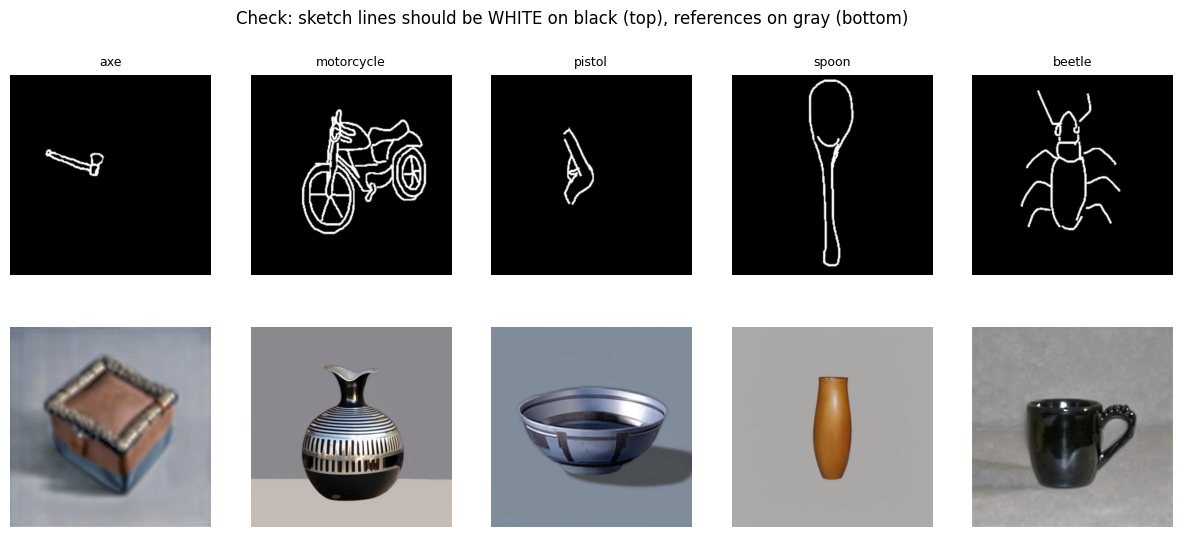

example caption: A person holds an axe above a pile of logs.


In [6]:
import matplotlib.pyplot as plt

def letterbox(im, size, fill):
    im = ImageOps.contain(im, (size, size), Image.LANCZOS)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return canvas

def prep_sketch(path):
    im = Image.open(path).convert("L")
    if np.array(im).mean() > 127:          # Sketchy: dark lines on white. ControlNet wants light lines on black.
        im = ImageOps.invert(im)
    if SKETCH_DILATE:
        im = im.filter(ImageFilter.MaxFilter(3))
    return letterbox(im.convert("RGB"), RES, (0, 0, 0))

def prep_ref(path):
    return letterbox(Image.open(path).convert("RGB"), RES, (127, 127, 127))

BLACK = Image.new("RGB", (RES, RES), (0, 0, 0))
GRAY = Image.new("RGB", (RES, RES), (127, 127, 127))

def seed_for(rid):
    return int(hashlib.md5(str(rid).encode()).hexdigest()[:8], 16)

fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for j, r in enumerate(rows[:5]):
    ax[0, j].imshow(prep_sketch(resolve(r["sketch"]))); ax[0, j].set_title(r["category"], fontsize=9)
    ax[1, j].imshow(prep_ref(resolve(r["reference"])))
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.suptitle("Check: sketch lines should be WHITE on black (top), references on gray (bottom)")
plt.show()
print("example caption:", rows[0]["caption"])

In [7]:
from huggingface_hub import list_repo_files
ip_files = list_repo_files(IP_REPO)
need = [f"{IP_SUBFOLDER}/{IP_WEIGHT}", f"{ENC_SUBFOLDER}/config.json"]
for n in need:
    print(("OK      " if n in ip_files else "MISSING ") + n)
if any(n not in ip_files for n in need):
    print("\nAvailable IP-Adapter SDXL files:")
    print("\n".join(f for f in ip_files if f.startswith(IP_SUBFOLDER)))
    raise FileNotFoundError("Pick an existing IP_WEIGHT from the list above.")

OK      sdxl_models/ip-adapter_sdxl_vit-h.safetensors
OK      models/image_encoder/config.json


In [8]:
import gc, psutil
from diffusers import (UNet2DConditionModel, ControlNetModel, AutoencoderKL,
                       StableDiffusionXLControlNetPipeline, EulerDiscreteScheduler)
from transformers import CLIPTextModel, CLIPTextModelWithProjection, CLIPTokenizer, CLIPVisionModelWithProjection

dt = torch.float16
def ram():
    return round(psutil.virtual_memory().used / 1e9, 1)
def gpu():
    return round(torch.cuda.memory_allocated() / 1e9, 2)
def to_gpu(m, name):
    m = m.to("cuda"); gc.collect()
    print(f"{name:12s} loaded | system RAM used {ram()} GB | GPU {gpu()} GB")
    return m

print("system RAM total (GB):", round(psutil.virtual_memory().total / 1e9, 1), "| used before load:", ram())
vae = to_gpu(AutoencoderKL.from_pretrained(VAE_ID, torch_dtype=dt), "vae")
unet = to_gpu(UNet2DConditionModel.from_pretrained(BASE_ID, subfolder="unet", torch_dtype=dt, variant="fp16"), "unet")
controlnet = to_gpu(ControlNetModel.from_pretrained(CN_ID, torch_dtype=dt), "controlnet")
te1 = to_gpu(CLIPTextModel.from_pretrained(BASE_ID, subfolder="text_encoder", torch_dtype=dt, variant="fp16"), "text enc 1")
te2 = to_gpu(CLIPTextModelWithProjection.from_pretrained(BASE_ID, subfolder="text_encoder_2", torch_dtype=dt, variant="fp16"), "text enc 2")
enc = to_gpu(CLIPVisionModelWithProjection.from_pretrained(IP_REPO, subfolder=ENC_SUBFOLDER, torch_dtype=dt), "image enc")
tok1 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer")
tok2 = CLIPTokenizer.from_pretrained(BASE_ID, subfolder="tokenizer_2")
scheduler = EulerDiscreteScheduler.from_pretrained(BASE_ID, subfolder="scheduler")

pipe = StableDiffusionXLControlNetPipeline(
    vae=vae, text_encoder=te1, text_encoder_2=te2, tokenizer=tok1, tokenizer_2=tok2,
    unet=unet, controlnet=controlnet, scheduler=scheduler, image_encoder=enc,
)
pipe.load_ip_adapter(IP_REPO, subfolder=IP_SUBFOLDER, weight_name=IP_WEIGHT)
pipe.vae.enable_slicing()
pipe.vae.enable_tiling()
pipe.set_progress_bar_config(disable=True)
print("pipeline ready | system RAM used", ram(), "GB | GPU", gpu(), "GB")

system RAM total (GB): 13.6 | used before load: 4.0


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/631 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

...

scheduler_config.json:   0%|          | 0.00/479 [00:00<?, ?B/s]

sdxl_models/ip-adapter_sdxl_vit-h.safete(…): reconstructing file:   0%|          |  0.00B /  698MB            

sdxl_models/ip-adapter_sdxl_vit-h.safete(…): downloading bytes:           |  0.00B            

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


pipeline ready | system RAM used 6.7 GB | GPU 11.4 GB


## Encode once, then free the encoders
Captions and reference images are encoded here for every row that will be used, then the text encoders and image encoder are deleted from the GPU.
Rows added later (a different split) need this cell re-run with the encoders still loaded, so set `SPLIT` and `RUN_GRID` before running it.

In [9]:
from tqdm.auto import tqdm

@torch.no_grad()
def encode_text(prompt):
    outs = pipe.encode_prompt(prompt=prompt, device="cuda", num_images_per_prompt=1,
                              do_classifier_free_guidance=True, negative_prompt=NEG)
    return [t.cpu() for t in outs]    # prompt, negative, pooled, negative pooled

@torch.no_grad()
def encode_ip(img):
    emb = pipe.prepare_ip_adapter_image_embeds(ip_adapter_image=img, ip_adapter_image_embeds=None,
                                               device="cuda", num_images_per_prompt=1,
                                               do_classifier_free_guidance=True)
    return [t.cpu() for t in emb]

COND = {}
for r in tqdm(rows + grid_rows, desc="encoding"):
    if r["id"] not in COND:
        COND[r["id"]] = {"text": encode_text(r["caption"]), "ip": encode_ip(prep_ref(resolve(r["reference"])))}
GRAY_IP = encode_ip(GRAY)
print("cached conditioning for", len(COND), "rows")

pipe.text_encoder = None
pipe.text_encoder_2 = None
pipe.image_encoder = None
del te1, te2, enc
gc.collect(); torch.cuda.empty_cache()
print("encoders freed | GPU", gpu(), "GB | system RAM used", ram(), "GB")

encoding:   0%|          | 0/20 [00:00<?, ?it/s]

cached conditioning for 20 rows
encoders freed | GPU 8.51 GB | system RAM used 7.0 GB


In [10]:
def generate(row, cs, ips, seed, sketch_img=None):
    sketch_img = sketch_img if sketch_img is not None else prep_sketch(resolve(row["sketch"]))
    c = COND[row["id"]]
    pe, npe, ppe, nppe = c["text"]
    pipe.set_ip_adapter_scale(float(ips))
    g = torch.Generator("cpu").manual_seed(seed)
    out = pipe(
        prompt_embeds=pe, negative_prompt_embeds=npe,
        pooled_prompt_embeds=ppe, negative_pooled_prompt_embeds=nppe,
        image=sketch_img if cs > 0 else BLACK,                 # ControlNet always runs; scale 0 = no effect
        ip_adapter_image_embeds=c["ip"] if ips > 0 else GRAY_IP,  # scale 0 = no effect
        controlnet_conditioning_scale=float(cs),
        num_inference_steps=STEPS, guidance_scale=CFG,
        height=RES, width=RES, generator=g,
    )
    return out.images[0]

## Sanity check (run before the full job)
Generates 4 rows in all 4 modes, shows the grid, and reports peak GPU memory and seconds per image.
Look for: text-only ignoring the shape, sketch modes following the outline, reference modes picking up color and material.

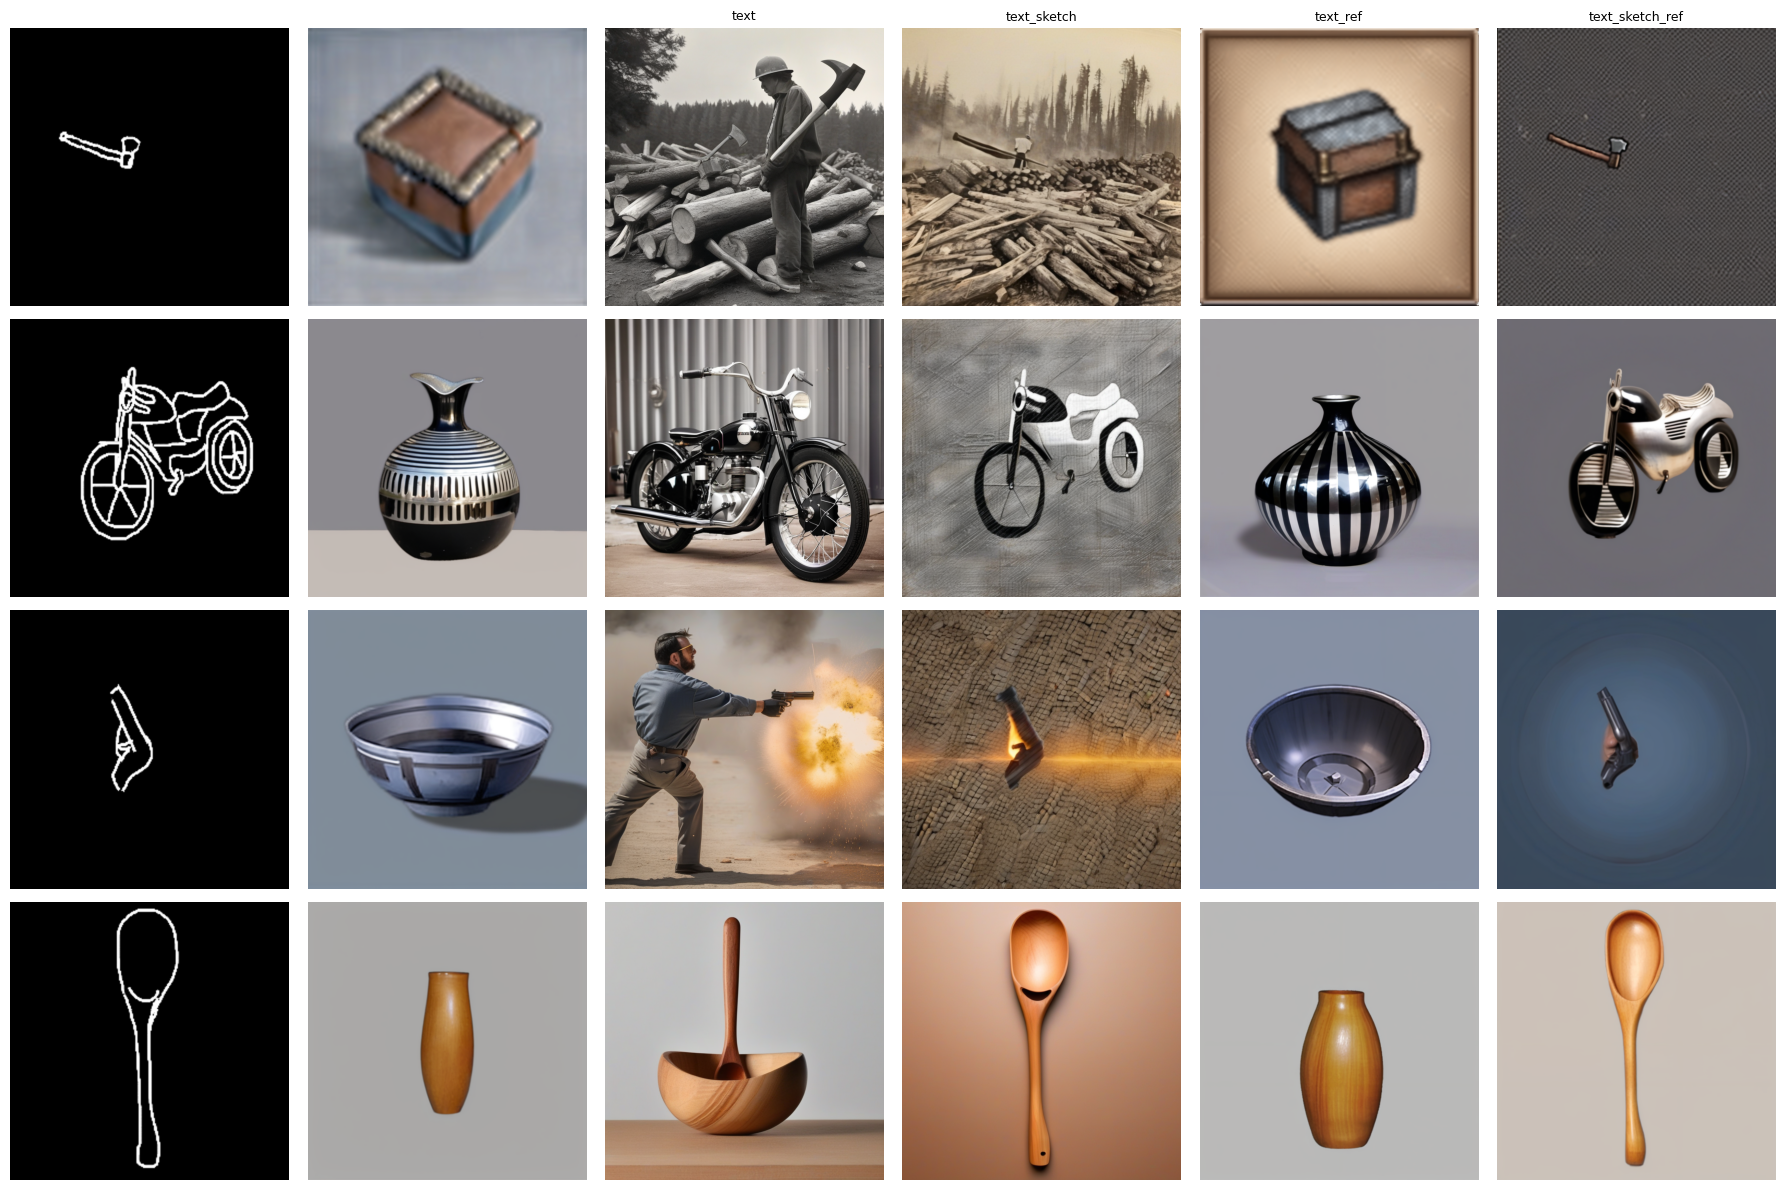

peak GPU allocated: 9.22 GB | reserved: 9.45 GB | 21.4 s/image
full test split, 4 modes: ~29 min


In [11]:
torch.cuda.reset_peak_memory_stats()
test_rows = rows[:4]
fig, ax = plt.subplots(len(test_rows), 2 + len(MODES), figsize=(3 * (2 + len(MODES)), 3 * len(test_rows)))
ax = np.atleast_2d(ax)
t0, n = time.time(), 0
for i, r in enumerate(test_rows):
    sk = prep_sketch(resolve(r["sketch"]))
    ax[i, 0].imshow(sk); ax[i, 1].imshow(prep_ref(resolve(r["reference"])))
    for j, (mode, (cs, ips)) in enumerate(MODES.items()):
        img = generate(r, cs, ips, seed_for(r["id"]), sk); n += 1
        ax[i, 2 + j].imshow(img)
        if i == 0: ax[i, 2 + j].set_title(mode, fontsize=9)
    for a in ax[i]: a.axis("off")
plt.tight_layout(); plt.show()
peak = torch.cuda.max_memory_allocated() / 1e9
per = (time.time() - t0) / n
print(f"peak GPU allocated: {peak:.2f} GB | reserved: {torch.cuda.max_memory_reserved() / 1e9:.2f} GB | {per:.1f} s/image")
print("full test split, 4 modes: ~%.0f min" % (len(rows) * len(MODES) * per / 60))
if peak > 13.0:
    print("WARNING: peak above 13 GB. Lower RES to 640 or 512 before the full run.")

## Full baseline run
Resumable: existing PNGs are skipped, so if Colab disconnects, reconnect, re-run the setup cells, then this cell.

In [12]:
from tqdm.auto import tqdm

def out_path(mode, rid):
    return f"{OUT_ROOT}/{mode}/{rid}.png"

for mode in MODES:
    os.makedirs(f"{OUT_ROOT}/{mode}", exist_ok=True)

torch.cuda.reset_peak_memory_stats()
for r in tqdm(rows, desc="rows"):
    todo = [(m, c) for m, c in MODES.items() if not os.path.exists(out_path(m, r["id"]))]
    if not todo:
        continue
    sk = prep_sketch(resolve(r["sketch"]))
    for mode, (cs, ips) in todo:
        generate(r, cs, ips, seed_for(r["id"]), sk).save(out_path(mode, r["id"]))
    torch.cuda.empty_cache()
print("peak GPU allocated (GB):", round(torch.cuda.max_memory_allocated() / 1e9, 2))

rows:   0%|          | 0/20 [00:00<?, ?it/s]

peak GPU allocated (GB): 9.22


In [13]:
manifest = []
for r in rows:
    for mode, (cs, ips) in MODES.items():
        p = out_path(mode, r["id"])
        if os.path.exists(p):
            manifest.append({
                "id": r["id"], "mode": mode, "category": r["category"], "caption": r["caption"],
                "target": r["target"], "sketch": r["sketch"], "reference": r["reference"],
                "generated": p, "controlnet_scale": cs, "ip_adapter_scale": ips, "seed": seed_for(r["id"]),
                "res": RES, "steps": STEPS, "cfg": CFG,
            })
with open(f"{OUT_ROOT}/manifest.jsonl", "w") as f:
    for m in manifest:
        f.write(json.dumps(m) + "\n")
print(f"manifest: {len(manifest)} of {len(rows) * len(MODES)} expected generations ->", f"{OUT_ROOT}/manifest.jsonl")

manifest: 80 of 80 expected generations -> /content/drive/MyDrive/sketchy_dataset_one_sketch/sdxl_runs/sdxl_baseline_v1/manifest.jsonl


## Optional: weight grid for gate targets (off by default)
Set `RUN_GRID = True` in the config cell before the encode step. For each training row, generate across a grid of (ControlNet scale, IP-Adapter scale) with the same seed. A later cell scores each image with `eval_metrics.py`, and the best weights per row become the regression targets for the gating MLP.
Cost is rows x grid points x s/image from the sanity cell, so check the estimate before enabling.

In [20]:
if RUN_GRID:
    n_img = len(grid_rows) * len(GRID_CS) * len(GRID_IP)
    print(f"{n_img} images; at ~{per:.0f} s/image that is ~{n_img * per / 3600:.1f} h" if "per" in globals() else f"{n_img} images")
    GRID_ROOT = f"{DRIVE_ROOT}/sdxl_runs/{RUN_NAME}_grid"
    for r in tqdm(grid_rows, desc="grid rows"):
        sk = prep_sketch(resolve(r["sketch"]))
        for cs in GRID_CS:
            for ips in GRID_IP:
                d = f"{GRID_ROOT}/cs{cs}_ip{ips}"
                os.makedirs(d, exist_ok=True)
                p = f"{d}/{r['id']}.png"
                if not os.path.exists(p):
                    generate(r, cs, ips, seed_for(r["id"]), sk).save(p)
        torch.cuda.empty_cache()
else:
    print("grid disabled (RUN_GRID = False)")

0 images; at ~21 s/image that is ~0.0 h


grid rows: 0it [00:00, ?it/s]